# Predictor Comparison
Compares three prediction strategies on the same train/test split:
- **Direct** — single LightGBM model predicting `total_points`
- **By Position** — one model per position (GK / DEF / MID / FWD)
- **Component** — separate models per scoring component, combined via FPL rules

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fplt.data import load_gameweeks, load_teams
from fplt.features import build_features
from fplt.predict import ByPositionPredictor, ComponentPredictor, LGBMPredictor
from fplt.predict.component import COMPONENTS

DATA_DIR = Path("..") / "data"
TRAIN_SEASON = "2022-23"
TEST_SEASON = "2023-24"
NUM_ROUNDS = 500
COMPONENT_COLS = [col for _, col, _, _ in COMPONENTS]

## 1. Prepare Data

In [13]:
df_train = build_features(
    load_gameweeks(TRAIN_SEASON, DATA_DIR), load_teams(TRAIN_SEASON, DATA_DIR)
)
df_test = build_features(
    load_gameweeks(TEST_SEASON, DATA_DIR), load_teams(TEST_SEASON, DATA_DIR)
)

df_train = df_train[df_train["GW"] > 1].copy()
df_test = df_test[df_test["GW"] > 1].copy()

y_train = df_train["total_points"]
y_test = df_test["total_points"]

print(f"Train: {len(df_train):,} rows | Test: {len(df_test):,} rows")

Train: 25,932 rows | Test: 29,067 rows


## 2. Train All Three Models

In [3]:
print("--- Direct ---")
direct = LGBMPredictor(num_rounds=NUM_ROUNDS)
direct.fit(df_train, y_train, X_val=df_test, y_val=y_test)

print("\n--- By Position ---")
by_pos = ByPositionPredictor(num_rounds=NUM_ROUNDS)
by_pos.fit(df_train, y_train, X_val=df_test, y_val=y_test)

print("\n--- Component ---")
component = ComponentPredictor(num_rounds=NUM_ROUNDS)
component.fit(
    df_train, df_train[COMPONENT_COLS], X_val=df_test, y_val=df_test[COMPONENT_COLS]
)

--- Direct ---

--- By Position ---
  [GK] trained on 2,735 rows
  [DEF] trained on 8,974 rows
  [MID] trained on 11,170 rows
  [FWD] trained on 3,053 rows

--- Component ---
  [minutes] trained
  [goals_scored] trained
  [assists] trained
  [clean_sheets] trained
  [saves] trained
  [bonus] trained
  [yellow_cards] trained


## 3. Overall Metrics

In [4]:
def metrics(name, preds, y):
    y_np = y.to_numpy()
    mae = np.mean(np.abs(preds - y_np))
    rmse = np.sqrt(np.mean((preds - y_np) ** 2))
    # correlation between predicted rank and actual rank per GW
    return {"model": name, "MAE": round(mae, 3), "RMSE": round(rmse, 3)}


preds_direct = direct.predict(df_test)
preds_by_pos = by_pos.predict(df_test)
preds_component = component.predict(df_test)

baseline_mae = np.mean(np.abs(y_train.mean() - y_test.to_numpy()))

results = pd.DataFrame(
    [
        {
            "model": "Baseline (mean)",
            "MAE": round(baseline_mae, 3),
            "RMSE": round(
                float(np.sqrt(np.mean((y_train.mean() - y_test.to_numpy()) ** 2))), 3
            ),
        },
        metrics("Direct", preds_direct, y_test),
        metrics("By Position", preds_by_pos, y_test),
        metrics("Component", preds_component, y_test),
    ]
)
results["MAE improvement"] = (
    (baseline_mae - results["MAE"]) / baseline_mae * 100
).round(1).astype(str) + "%"
results

,model,MAE,RMSE,MAE improvement
0,Baseline (mean),1.476,2.299,-0.0%
1,Direct,0.955,1.938,35.3%
2,By Position,0.974,1.958,34.0%
3,Component,1.466,2.072,0.7%


## 4. Metrics by Position

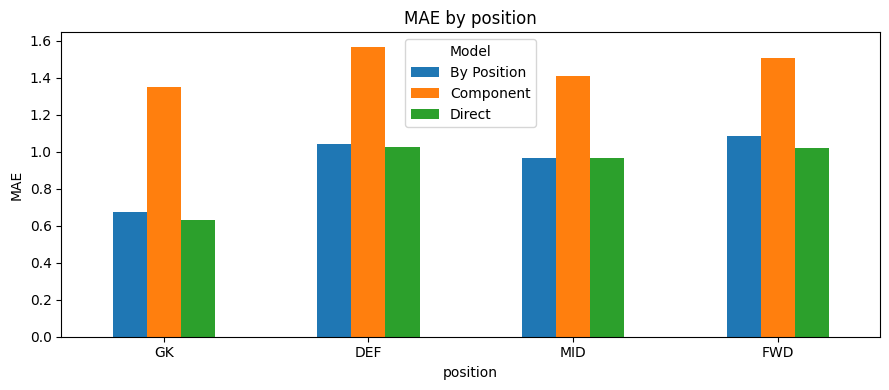

model,By Position,Component,Direct
position,,,
GK,0.673,1.349,0.634
DEF,1.044,1.568,1.025
MID,0.968,1.409,0.969
FWD,1.083,1.510,1.021


In [5]:
pos_results = []
for pos in ["GK", "DEF", "MID", "FWD"]:
    mask = df_test["position"] == pos
    y_pos = y_test[mask].to_numpy()
    for name, preds in [
        ("Direct", preds_direct),
        ("By Position", preds_by_pos),
        ("Component", preds_component),
    ]:
        mae = np.mean(np.abs(preds[mask] - y_pos))
        pos_results.append({"position": pos, "model": name, "MAE": round(mae, 3)})

pos_df = pd.DataFrame(pos_results).pivot(
    index="position", columns="model", values="MAE"
)
pos_df = pos_df.loc[["GK", "DEF", "MID", "FWD"]]

fig, ax = plt.subplots(figsize=(9, 4))
pos_df.plot.bar(ax=ax, rot=0)
ax.set_title("MAE by position")
ax.set_ylabel("MAE")
ax.legend(title="Model")
plt.tight_layout()
plt.show()
pos_df

## 5. Predicted vs Actual — Side by Side

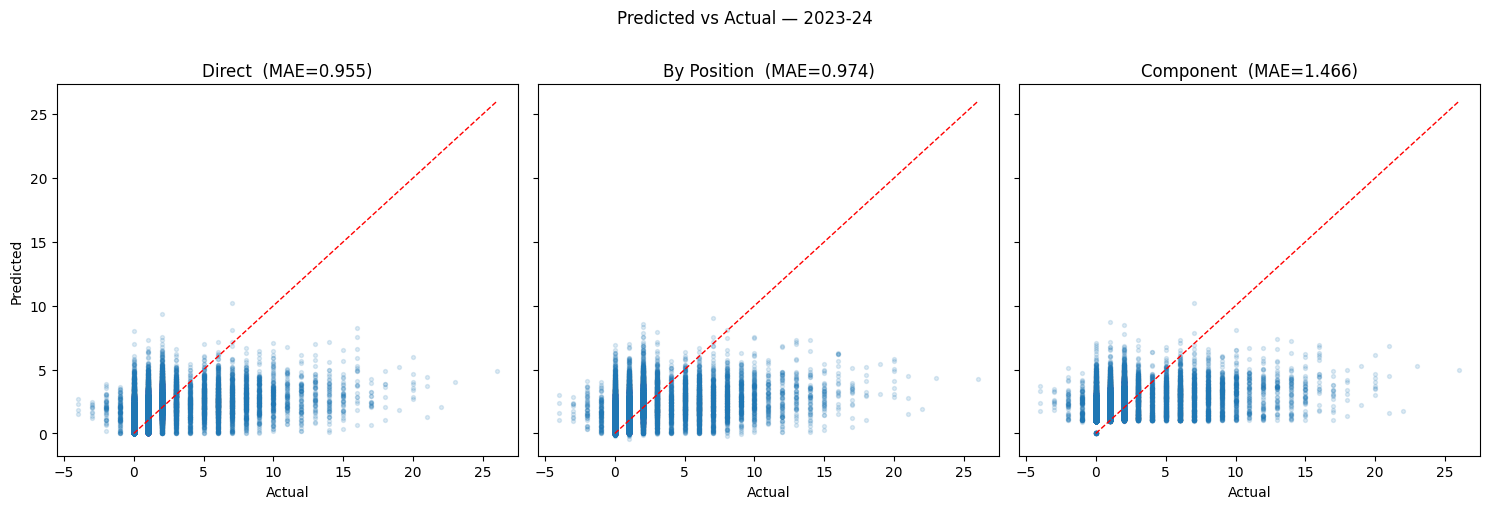

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, sharex=True)
y_np = y_test.to_numpy()

for ax, name, preds in zip(
    axes,
    ["Direct", "By Position", "Component"],
    [preds_direct, preds_by_pos, preds_component],
):
    ax.scatter(y_np, preds, alpha=0.15, s=8)
    lim = max(y_np.max(), preds.max())
    ax.plot([0, lim], [0, lim], "r--", linewidth=1)
    mae = np.mean(np.abs(preds - y_np))
    ax.set_title(f"{name}  (MAE={mae:.3f})")
    ax.set_xlabel("Actual")

axes[0].set_ylabel("Predicted")
plt.suptitle(f"Predicted vs Actual — {TEST_SEASON}", y=1.01)
plt.tight_layout()
plt.show()

## 6. Top-K Accuracy
For each GW, what fraction of the top-K actual scorers did each model correctly identify?

In [7]:
def topk_accuracy(df, preds, y, k=10):
    hits = []
    for gw in df["GW"].unique():
        mask = (df["GW"] == gw).to_numpy()
        if mask.sum() < k:
            continue
        actual_top = set(np.argsort(y.to_numpy()[mask])[-k:])
        pred_top = set(np.argsort(preds[mask])[-k:])
        hits.append(len(actual_top & pred_top) / k)
    return np.mean(hits)


for name, preds in [
    ("Direct", preds_direct),
    ("By Position", preds_by_pos),
    ("Component", preds_component),
]:
    acc = topk_accuracy(df_test, preds, y_test, k=10)
    print(f"{name:15s}  Top-10 accuracy: {acc:.1%}")

Direct           Top-10 accuracy: 9.2%
By Position      Top-10 accuracy: 8.6%
Component        Top-10 accuracy: 9.7%


## 7. Component Predictor — Predicted vs Actual per Component

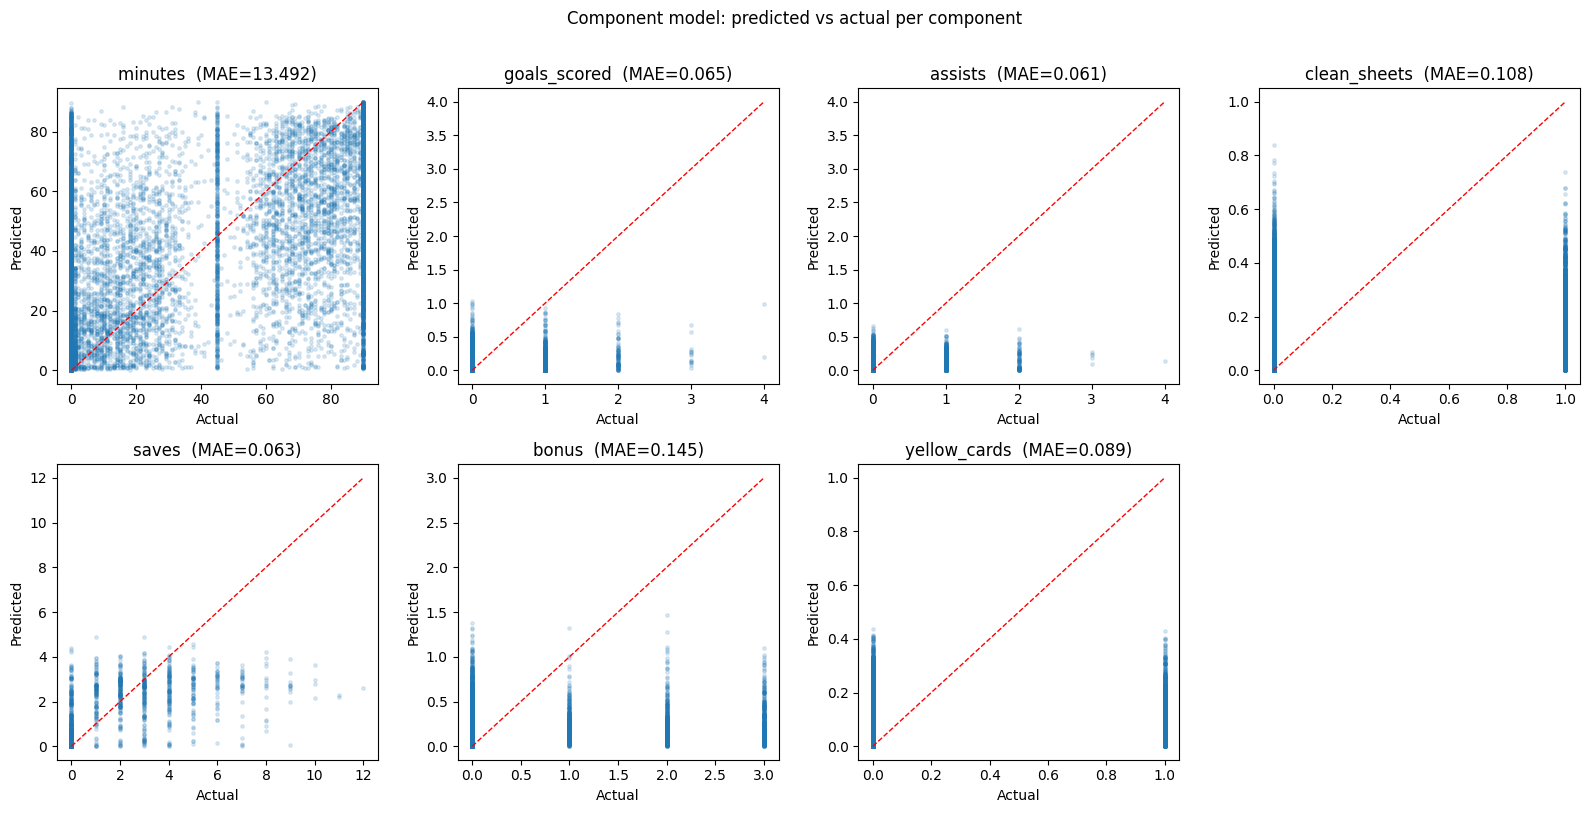

In [8]:
comp_preds = component.predict_components(df_test)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (name, col, _, _) in enumerate(COMPONENTS):
    ax = axes[i]
    actual = df_test[col].to_numpy()
    pred = comp_preds[name].to_numpy()
    mae = np.mean(np.abs(pred - actual))
    ax.scatter(actual, pred, alpha=0.15, s=6)
    lim = max(actual.max(), pred.max()) if actual.max() > 0 else 1
    ax.plot([0, lim], [0, lim], "r--", linewidth=1)
    ax.set_title(f"{name}  (MAE={mae:.3f})")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

# Hide unused subplot
for j in range(len(COMPONENTS), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Component model: predicted vs actual per component", y=1.01)
plt.tight_layout()
plt.show()

## 8. Feature Importance Comparison (top 15)

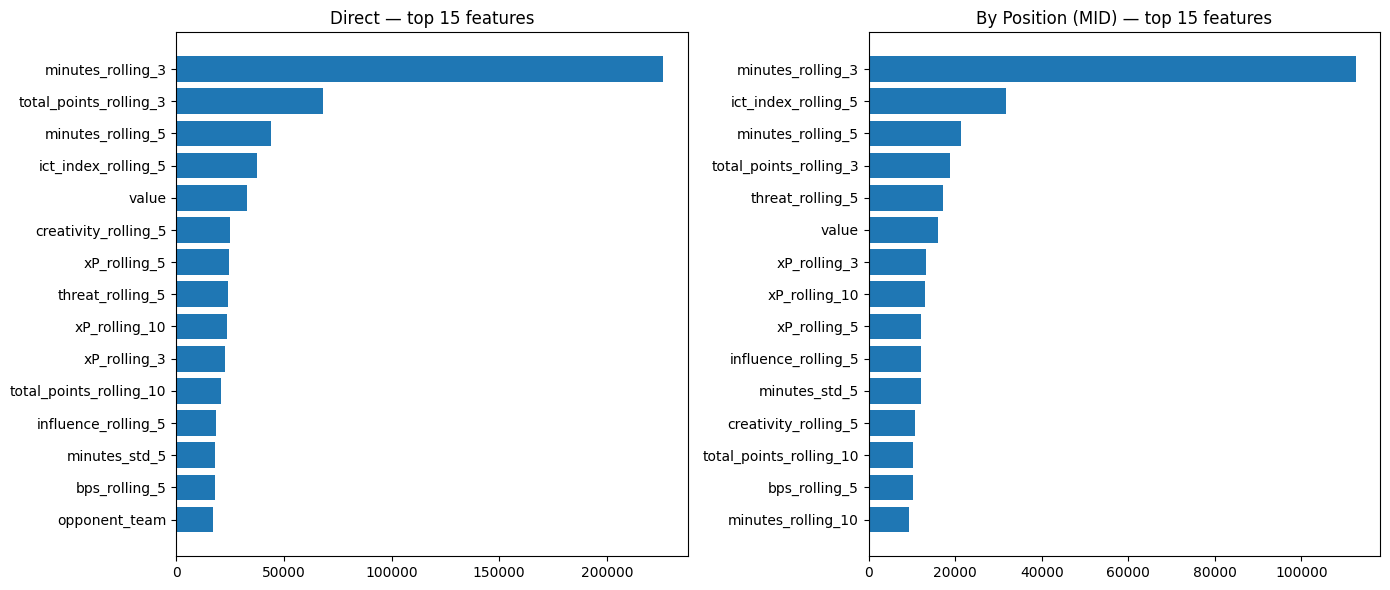

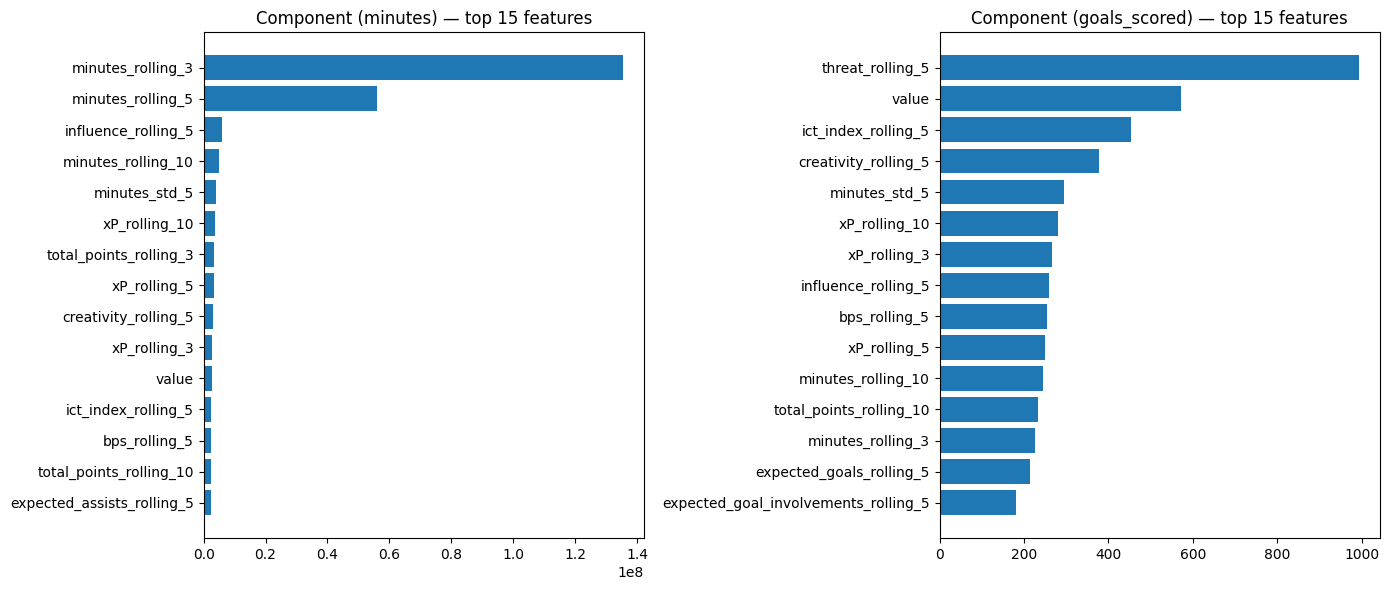

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Direct model
fi_direct = direct.feature_importance().head(15)
axes[0].barh(fi_direct["feature"][::-1], fi_direct["importance"][::-1])
axes[0].set_title("Direct — top 15 features")

# By Position — show MID model as representative
fi_mid = by_pos.feature_importance()["MID"].head(15)
axes[1].barh(fi_mid["feature"][::-1], fi_mid["importance"][::-1])
axes[1].set_title("By Position (MID) — top 15 features")

plt.tight_layout()
plt.show()

# Component model — show minutes and goals models
fi_comp = component.feature_importance()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, comp_name in zip(axes, ["minutes", "goals_scored"]):
    fi = fi_comp[comp_name].head(15)
    ax.barh(fi["feature"][::-1], fi["importance"][::-1])
    ax.set_title(f"Component ({comp_name}) — top 15 features")
plt.tight_layout()
plt.show()